# TelcoPeople — Stabilisation multi-temporelle du modèle avec clustering

Ce notebook consolide le meilleur socle actuel : **CatBoost enrichi par clustering et détection d’anomalies**.

Objectifs :

1. évaluer le modèle sur plusieurs périodes futures successives ;
2. produire des prédictions hors échantillon temporelles ;
3. choisir un seuil global robuste plutôt qu’un seuil optimisé sur une seule période ;
4. mesurer la stabilité du F1, de la précision, du rappel et de l’AUC ;
5. comparer la version avec clustering à une baseline identique sans clustering.

Le score de référence à confirmer est un F1 de **0,3268** sur juin 2024.

## 1. Bibliothèques

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score
from catboost import CatBoostClassifier

pd.set_option("display.max_columns", 150)
sns.set_theme(style="whitegrid")

## 2. Chargement des données

In [2]:
CHEMIN = "../data/raw/"
train = pd.read_csv(CHEMIN + "telcopeople_train.csv")
test = pd.read_csv(CHEMIN + "telcopeople_test.csv")

print("Train :", train.shape)
print("Test :", test.shape)

Train : (5444, 42)
Test : (1507, 41)


## 3. Préparation métier commune

In [3]:
def preparer_donnees(df):
    df = df.copy()

    df["ville_affectation"] = df["ville_affectation"].fillna("INCONNU").str.strip().str.title()
    df["departement"] = df["departement"].fillna("INCONNU").str.strip().str.upper().str.replace("DEPT", "DEP", regex=False)
    df["contrat"] = df["contrat"].fillna("INCONNU").str.strip().str.upper().str.replace(".", "", regex=False)
    df["niveau_etude"] = df["niveau_etude"].fillna("INCONNU").str.strip().str.upper().str.replace(" ", "", regex=False).str.replace("BAC2", "BAC+2", regex=False)

    for col in ["genre", "poste", "grade", "code_site", "source_sirh"]:
        df[col] = df[col].fillna("INCONNU").astype(str).str.strip().str.upper()

    for col in ["date_reference", "date_naissance", "date_embauche", "date_derniere_promotion", "date_derniere_absence"]:
        df[col] = pd.to_datetime(df[col], format="mixed", dayfirst=True, errors="coerce")

    df["salaire_mensuel"] = pd.to_numeric(
        df["salaire_mensuel"].astype(str).str.replace("FCFA", "", regex=False).str.replace(" ", "", regex=False),
        errors="coerce"
    )

    df["age"] = (df["date_reference"] - df["date_naissance"]).dt.days / 365.25
    df["anciennete"] = (df["date_reference"] - df["date_embauche"]).dt.days / 365.25
    df["annees_depuis_promotion"] = (df["date_reference"] - df["date_derniere_promotion"]).dt.days / 365.25
    df["jours_depuis_absence"] = (df["date_reference"] - df["date_derniere_absence"]).dt.days

    df["ratio_salaire_reference"] = df["salaire_mensuel"] / df["reference_salaire_grade"]
    df["ecart_salaire_reference"] = df["salaire_mensuel"] - df["reference_salaire_grade"]
    df["evolution_salaire"] = df["salaire_mensuel"] - df["salaire_12m_avant"]
    df["taux_evolution_salaire"] = df["evolution_salaire"] / df["salaire_12m_avant"].replace(0, np.nan)

    df["engagement_moyen"] = df[["engagement_actuel", "engagement_precedent"]].mean(axis=1)
    df["evolution_engagement"] = df["engagement_actuel"] - df["engagement_precedent"]
    df["performance_moyenne"] = df[["performance_actuelle", "performance_precedente"]].mean(axis=1)
    df["evolution_performance"] = df["performance_actuelle"] - df["performance_precedente"]

    df["jours_abs_6m"] = df[[f"jours_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["nb_abs_6m"] = df[[f"nb_abs_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["abs_non_just_6m"] = df[[f"abs_non_just_m{i}" for i in range(1, 7)]].sum(axis=1)
    df["jours_abs_recents"] = df[["jours_abs_m1", "jours_abs_m2", "jours_abs_m3"]].sum(axis=1)
    df["jours_abs_anciens"] = df[["jours_abs_m4", "jours_abs_m5", "jours_abs_m6"]].sum(axis=1)
    df["tendance_absence"] = df["jours_abs_recents"] - df["jours_abs_anciens"]

    df["jamais_promu"] = df["date_derniere_promotion"].isna().astype(int)
    df["absence_non_renseignee"] = df["date_derniere_absence"].isna().astype(int)
    df["engagement_manquant"] = df["engagement_actuel"].isna().astype(int)
    df["performance_manquante"] = df["performance_actuelle"].isna().astype(int)

    return df.replace([np.inf, -np.inf], np.nan)

train_prepare = preparer_donnees(train)
test_prepare = preparer_donnees(test)

## 4. Fenêtres de validation temporelle

Chaque période est prédite uniquement à partir des périodes antérieures. Les deux premières périodes historiques sont nécessaires pour démarrer l’apprentissage.

In [4]:
PERIODES_VALIDATION = [
    pd.Timestamp("2023-06-30"),
    pd.Timestamp("2023-12-31"),
    pd.Timestamp("2024-06-30")
]

for periode in PERIODES_VALIDATION:
    print(
        periode.date(),
        "| apprentissage :", (train_prepare["date_reference"] < periode).sum(),
        "| validation :", (train_prepare["date_reference"] == periode).sum()
    )

2023-06-30 | apprentissage : 1858 | validation : 1083
2023-12-31 | apprentissage : 2941 | validation : 1189
2024-06-30 | apprentissage : 4130 | validation : 1314


## 5. Variables utilisées par le clustering

In [5]:
VARIABLES_NUM_CLUSTER = [
    "age", "anciennete", "annees_depuis_promotion",
    "ratio_salaire_reference", "taux_evolution_salaire",
    "engagement_actuel", "engagement_precedent", "engagement_moyen",
    "performance_actuelle", "performance_precedente", "performance_moyenne",
    "jours_abs_6m", "nb_abs_6m", "abs_non_just_6m",
    "tendance_absence", "taille_departement"
]
VARIABLES_CAT_CLUSTER = ["contrat", "grade", "departement", "code_site"]
VARIABLES_CLUSTER = VARIABLES_NUM_CLUSTER + VARIABLES_CAT_CLUSTER

## 6. Construction des variables non supervisées dans chaque fenêtre

Le préprocesseur, K-Means et Isolation Forest sont réappris à chaque fenêtre uniquement sur le passé.

In [6]:
def enrichir_fold(train_fold, validation_fold, k=7):
    train_fold = train_fold.copy()
    validation_fold = validation_fold.copy()

    preprocesseur = ColumnTransformer([
        ("num", Pipeline([
            ("imputation", SimpleImputer(strategy="median")),
            ("standardisation", StandardScaler())
        ]), VARIABLES_NUM_CLUSTER),
        ("cat", Pipeline([
            ("imputation", SimpleImputer(strategy="most_frequent")),
            ("encodage", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), VARIABLES_CAT_CLUSTER)
    ])

    Z_train = preprocesseur.fit_transform(train_fold[VARIABLES_CLUSTER])
    Z_validation = preprocesseur.transform(validation_fold[VARIABLES_CLUSTER])

    kmeans = KMeans(n_clusters=k, random_state=42, n_init=20).fit(Z_train)
    isolation = IsolationForest(
        n_estimators=500,
        contamination=0.03,
        random_state=42,
        n_jobs=-1
    ).fit(Z_train)

    def ajouter(df, matrice):
        distances = kmeans.transform(matrice)
        distances_triees = np.sort(distances, axis=1)
        df["cluster_rh"] = distances.argmin(axis=1).astype(str)
        df["distance_cluster"] = distances_triees[:, 0]
        df["marge_cluster"] = distances_triees[:, 1] - distances_triees[:, 0]
        df["score_anomalie"] = -isolation.score_samples(matrice)
        return df

    return ajouter(train_fold, Z_train), ajouter(validation_fold, Z_validation)

## 7. Fonction d’évaluation d’une fenêtre

La fonction entraîne deux modèles identiques : une baseline sans variables non supervisées et une version enrichie.

In [7]:
COLONNES_RETRAIT = [
    "target", "id", "date_reference", "date_naissance", "date_embauche",
    "date_derniere_promotion", "date_derniere_absence"
]
VARIABLES_NON_SUPERVISEES = [
    "cluster_rh", "distance_cluster", "marge_cluster", "score_anomalie"
]

def entrainer_catboost(X_train, y_train, X_val, y_val):
    cat_cols = X_train.select_dtypes(include=["object", "string"]).columns.tolist()
    modele = CatBoostClassifier(
        iterations=1500,
        learning_rate=0.03,
        depth=6,
        l2_leaf_reg=7,
        loss_function="Logloss",
        eval_metric="AUC",
        auto_class_weights="Balanced",
        random_seed=42,
        verbose=False
    )
    modele.fit(
        X_train, y_train,
        cat_features=cat_cols,
        eval_set=(X_val, y_val),
        early_stopping_rounds=150
    )
    return modele, modele.predict_proba(X_val)[:, 1]

def evaluer_fenetre(periode):
    train_fold = train_prepare.loc[train_prepare["date_reference"] < periode].copy()
    val_fold = train_prepare.loc[train_prepare["date_reference"] == periode].copy()

    train_enrichi, val_enrichi = enrichir_fold(train_fold, val_fold)

    X_train_enrichi = train_enrichi.drop(columns=COLONNES_RETRAIT)
    X_val_enrichi = val_enrichi.drop(columns=COLONNES_RETRAIT)
    X_train_base = X_train_enrichi.drop(columns=VARIABLES_NON_SUPERVISEES)
    X_val_base = X_val_enrichi.drop(columns=VARIABLES_NON_SUPERVISEES)

    y_train = train_enrichi["target"]
    y_val = val_enrichi["target"]

    modele_base, proba_base = entrainer_catboost(X_train_base, y_train, X_val_base, y_val)
    modele_cluster, proba_cluster = entrainer_catboost(X_train_enrichi, y_train, X_val_enrichi, y_val)

    predictions = pd.DataFrame({
        "id": val_fold["id"].values,
        "periode": periode,
        "target": y_val.values,
        "proba_baseline": proba_base,
        "proba_clustering": proba_cluster
    })

    diagnostic = pd.DataFrame([
        {
            "periode": periode,
            "modele": "Baseline",
            "auc": roc_auc_score(y_val, proba_base),
            "iteration": modele_base.get_best_iteration()
        },
        {
            "periode": periode,
            "modele": "Clustering",
            "auc": roc_auc_score(y_val, proba_cluster),
            "iteration": modele_cluster.get_best_iteration()
        }
    ])

    return predictions, diagnostic

## 8. Exécution des validations temporelles

In [8]:
predictions_folds = []
diagnostics_folds = []

for periode in PERIODES_VALIDATION:
    print("Validation :", periode.date())
    predictions, diagnostic = evaluer_fenetre(periode)
    predictions_folds.append(predictions)
    diagnostics_folds.append(diagnostic)

predictions_oof = pd.concat(predictions_folds, ignore_index=True)
diagnostics = pd.concat(diagnostics_folds, ignore_index=True)

display(diagnostics)

Validation : 2023-06-30
Validation : 2023-12-31
Validation : 2024-06-30


,periode,modele,auc,iteration
0,2023-06-30,Baseline,0.660570,147
1,2023-06-30,Clustering,0.668295,300
2,2023-12-31,Baseline,0.714920,133
3,2023-12-31,Clustering,0.718036,154
4,2024-06-30,Baseline,0.718804,191
5,2024-06-30,Clustering,0.715841,249


## 9. Recherche du seuil global hors temps

Un seuil unique est choisi à partir de l’ensemble des prédictions temporelles. Cette stratégie est plus robuste qu’un seuil optimisé uniquement sur juin 2024.

In [9]:
def analyser_seuils(colonne_probabilite, nom_modele):
    lignes = []
    for seuil in np.arange(0.20, 0.81, 0.01):
        pred = (predictions_oof[colonne_probabilite] >= seuil).astype(int)
        lignes.append({
            "modele": nom_modele,
            "seuil": round(float(seuil), 2),
            "f1": f1_score(predictions_oof["target"], pred),
            "precision": precision_score(predictions_oof["target"], pred, zero_division=0),
            "rappel": recall_score(predictions_oof["target"], pred, zero_division=0)
        })
    return pd.DataFrame(lignes)

seuils_base = analyser_seuils("proba_baseline", "Baseline")
seuils_cluster = analyser_seuils("proba_clustering", "Clustering")
seuils = pd.concat([seuils_base, seuils_cluster], ignore_index=True)

meilleurs_seuils = seuils.loc[seuils.groupby("modele")["f1"].idxmax()].sort_values("f1", ascending=False)
display(meilleurs_seuils)

,modele,seuil,f1,precision,rappel
101,Clustering,0.59,0.297297,0.252390,0.361644
37,Baseline,0.57,0.289157,0.228209,0.394521


## 10. Performance par période avec le seuil global

Le seuil global est appliqué séparément à chaque période afin de mesurer la stabilité réelle.

In [10]:
resultats_par_periode = []

for _, ligne in meilleurs_seuils.iterrows():
    nom = ligne["modele"]
    seuil = ligne["seuil"]
    colonne = "proba_baseline" if nom == "Baseline" else "proba_clustering"

    for periode, groupe in predictions_oof.groupby("periode"):
        pred = (groupe[colonne] >= seuil).astype(int)
        resultats_par_periode.append({
            "modele": nom,
            "periode": periode,
            "seuil_global": seuil,
            "effectif": len(groupe),
            "departs_reels": int(groupe["target"].sum()),
            "positifs_predits": int(pred.sum()),
            "f1": f1_score(groupe["target"], pred),
            "precision": precision_score(groupe["target"], pred, zero_division=0),
            "rappel": recall_score(groupe["target"], pred, zero_division=0),
            "auc": roc_auc_score(groupe["target"], groupe[colonne])
        })

resultats_par_periode = pd.DataFrame(resultats_par_periode)
display(resultats_par_periode)

,modele,periode,seuil_global,effectif,departs_reels,positifs_predits,f1,precision,rappel,auc
0,Clustering,2023-06-30,0.59,1083,106,115,0.208145,0.200000,0.216981,0.668295
1,Clustering,2023-12-31,0.59,1189,130,166,0.331081,0.295181,0.376923,0.718036
2,Clustering,2024-06-30,0.59,1314,129,242,0.323450,0.247934,0.465116,0.715841
3,Baseline,2023-06-30,0.57,1083,106,187,0.225256,0.176471,0.311321,0.660570
4,Baseline,2023-12-31,0.57,1189,130,205,0.328358,0.268293,0.423077,0.714920
5,Baseline,2024-06-30,0.57,1314,129,239,0.304348,0.234310,0.434109,0.718804


## 11. Synthèse de stabilité

Le modèle à retenir doit présenter un F1 moyen élevé et un écart-type raisonnable entre périodes.

In [11]:
synthese = resultats_par_periode.groupby("modele").agg(
    f1_moyen=("f1", "mean"),
    f1_minimum=("f1", "min"),
    f1_maximum=("f1", "max"),
    f1_ecart_type=("f1", "std"),
    auc_moyenne=("auc", "mean"),
    precision_moyenne=("precision", "mean"),
    rappel_moyen=("rappel", "mean")
).sort_values("f1_moyen", ascending=False)

display(synthese)

,f1_moyen,f1_minimum,f1_maximum,f1_ecart_type,auc_moyenne,precision_moyenne,rappel_moyen
modele,,,,,,,
Clustering,0.287559,0.208145,0.331081,0.068880,0.700724,0.247705,0.353007
Baseline,0.285987,0.225256,0.328358,0.053948,0.698098,0.226358,0.389502


## 12. Visualisation de la stabilité temporelle

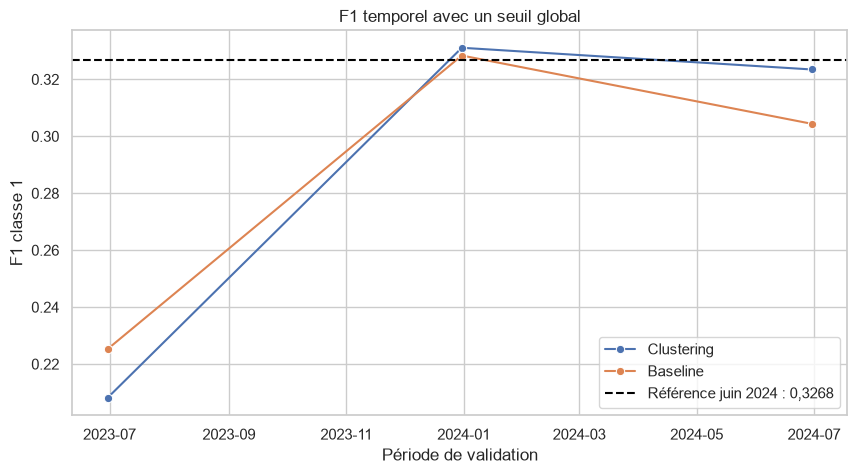

In [12]:
plt.figure(figsize=(10, 5))
sns.lineplot(
    data=resultats_par_periode,
    x="periode",
    y="f1",
    hue="modele",
    marker="o"
)
plt.axhline(0.3268, color="black", linestyle="--", label="Référence juin 2024 : 0,3268")
plt.title("F1 temporel avec un seuil global")
plt.xlabel("Période de validation")
plt.ylabel("F1 classe 1")
plt.legend()
plt.show()

## 13. Sensibilité du F1 autour du meilleur seuil

Un seuil robuste doit conserver un score raisonnable lorsqu’il varie légèrement.

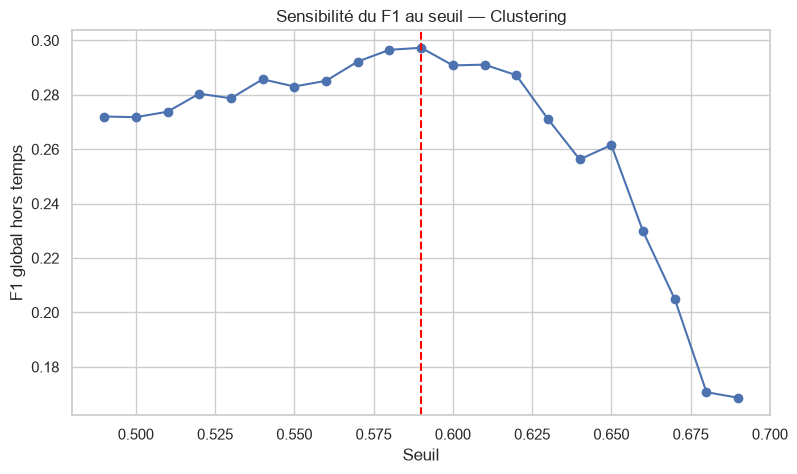

In [13]:
meilleur_modele = synthese.index[0]
colonne = "proba_baseline" if meilleur_modele == "Baseline" else "proba_clustering"
seuil_optimal = float(meilleurs_seuils.loc[meilleurs_seuils["modele"] == meilleur_modele, "seuil"].iloc[0])

zone = seuils.loc[
    (seuils["modele"] == meilleur_modele) &
    (seuils["seuil"].between(seuil_optimal - 0.10, seuil_optimal + 0.10))
]

plt.figure(figsize=(9, 5))
plt.plot(zone["seuil"], zone["f1"], marker="o")
plt.axvline(seuil_optimal, color="red", linestyle="--")
plt.title(f"Sensibilité du F1 au seuil — {meilleur_modele}")
plt.xlabel("Seuil")
plt.ylabel("F1 global hors temps")
plt.show()

## 14. Décision automatique

Cette cellule indique le meilleur modèle stable, son seuil global et ses performances moyennes.

In [14]:
print("Meilleur modèle multi-temporel :", meilleur_modele)
print("Seuil global :", seuil_optimal)
print("F1 moyen :", round(synthese.loc[meilleur_modele, "f1_moyen"], 4))
print("F1 minimum :", round(synthese.loc[meilleur_modele, "f1_minimum"], 4))
print("AUC moyenne :", round(synthese.loc[meilleur_modele, "auc_moyenne"], 4))
print("Précision moyenne :", round(synthese.loc[meilleur_modele, "precision_moyenne"], 4))
print("Rappel moyen :", round(synthese.loc[meilleur_modele, "rappel_moyen"], 4))

Meilleur modèle multi-temporel : Clustering
Seuil global : 0.59
F1 moyen : 0.2876
F1 minimum : 0.2081
AUC moyenne : 0.7007
Précision moyenne : 0.2477
Rappel moyen : 0.353


## 15. Export du journal de validation

Aucune soumission n’est produite. Les résultats sont enregistrés afin de préparer le modèle final lorsque la plateforme ouvrira.

In [15]:
predictions_oof.to_csv("../reports/predictions_hors_temps_clustering.csv", index=False)
diagnostics.to_csv("../reports/diagnostics_multi_temporels.csv", index=False)
resultats_par_periode.to_csv("../reports/resultats_multi_temporels_seuil_global.csv", index=False)
synthese.to_csv("../reports/synthese_stabilite_modeles.csv")
meilleurs_seuils.to_csv("../reports/seuils_globaux_modeles.csv", index=False)

print("Exports terminés dans reports.")

Exports terminés dans reports.


## Conclusion

Ce notebook doit permettre de répondre à trois questions :

1. le gain du clustering se répète-t-il sur plusieurs périodes ?
2. le seuil retenu reste-t-il efficace dans le temps ?
3. le F1 de juin 2024 est-il représentatif ou exceptionnel ?

Le modèle final sera construit seulement après cette vérification. Le score de référence ne sera plus un maximum obtenu sur une seule fenêtre, mais une performance temporelle moyenne accompagnée de son niveau de stabilité.